# Program 12: CLU with DER++ and BadTeacher: see spill and relapse

**What:** run DER++ with BadTeacher unlearning on a stream, and track every task's accuracy after every request.

**How:** on `L`, train with DER++. On `U`, run BadTeacher using the forget class's buffer samples as forget data and the rest of the buffer as retain data, then remove those samples from the buffer. Log a full accuracy matrix (request × task). Plot task 0's accuracy across the whole sequence.

**Why:** this reproduces UnCLe's key figure. Seeing it yourself is what turns the paper into *your* problem.

**Understanding note:** two separate failures. **Spill:** unlearning one task drops accuracy on others. **Relapse:** a forgotten task's accuracy climbs back after later learning.

**Done when:** your plot clearly shows at least one spill drop and one relapse rise.

## Where this fits (for a first-time reader)

This program puts together three earlier pieces:

| Piece | From | Role here |
|---|---|---|
| request stream | program 11 (`results/streams/*.json`) | the order of learn (`L`) and unlearn (`U`) requests |
| DER++ | program 06 (`common/derpp.py`) | how the model **learns** a task, with a 2,000-image buffer of old images and their stored logits |
| BadTeacher | program 09 (now `common/badteacher.py`) | how the model **forgets**: copy a random network on the forgotten images, copy itself on the rest |

For each request in the stream:
- `L t`: train task t with DER++ (5 epochs, as in program 06).
- `U i`: run BadTeacher on item i (a task, or a class at class level), then **delete** its images from the buffer.
- then measure the accuracy of **every class** on its test images.

That gives a table, request × class, and from it we look for the two failures:

- **Spill:** right after `U3`, do tasks that were *not* forgotten drop? Unlearning should hit only its target.
- **Relapse:** task 3 is forgotten at request r. Later the model learns other tasks, but never task 3 again (program 11's rule 3). If task 3's accuracy **rises** anyway, the knowledge came back by itself.

Terms: **class-IL accuracy** = the model picks among all 100 outputs (chance 1%). **Task-IL accuracy** = the model is told the task and picks among its 10 outputs (chance 10%). Task-IL is the more sensitive relapse detector: a forgotten task can easily lose the class-IL competition but still be told apart within its own 10 classes.

## 1. Setup

- `stream`: which saved stream to run (a file name in `results/streams/`, without `.json`). The default `task15_seed0` is `L5 → L2 → L3 → L4 → U5 → L9 → L0 → U3 → U2 → L8 → U8 → L7 → L6 → L1 → U4`.
- DER++ settings: the same as program 06.
- BadTeacher settings: the same as program 09 (Adam, lr 1e-4), with a fixed `unlearn_steps` per request. Program 09 reached FA ≈ 0 within about 10 steps, so 50 is plenty.
- `min_forget`: the buffer may hold only a few images of the forgotten item (at class level, sometimes 0). If it holds fewer than this, the rest is taken from that item's training images. A deletion request comes with the data to delete, so that data is available at that moment.
- `purge_buffer`: True deletes the forgotten item's buffer images after unlearning (the roadmap's rule). Program 15 compares this with False.

**Time:** about 15 minutes for `task15` (10 tasks of DER++ like program 06, plus about 10 s per `U`).
**Memory:** 2 loader workers during `L` only (closed after each task), test images loaded once into GPU memory (about 120 MB).

In [1]:
import copy, gc, sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

# Reload the shared code, so edits to common/ are picked up even without restarting the kernel.
import importlib
import common.utils, common.data, common.models, common.train, common.derpp, common.badteacher, common.stream
for module in (common.utils, common.data, common.models, common.train, common.derpp, common.badteacher, common.stream):
    importlib.reload(module)

import matplotlib.pyplot as plt
import numpy as np
import torch

from common.badteacher import badteacher_unlearn, make_bad_teacher
from common.data import N_TASKS, SplitCIFAR100, task_classes
from common.derpp import DERBuffer, train_one_epoch_derpp
from common.models import resnet18_cifar
from common.stream import learning_after_forget, load_stream, stream_to_str
from common.utils import RESULTS_DIR, get_device, log_run, set_seed

SETTINGS = {
    "stream": "task15_seed0",     # a file in results/streams/ (program 11), without .json
    "seed": 0,
    "workers": 2,                 # loader workers while learning a task (closed afterwards)
    # DER++ (program 06)
    "epochs": 5, "lr": 0.03, "batch_size": 32,
    "buffer_size": 2000, "replay_batch": 32, "alpha": 0.5, "beta": 0.5,
    # BadTeacher (program 09)
    "unlearn_lr": 1e-4,
    "unlearn_steps": 50,          # BadTeacher updates per U request
    "forget_batch": 64,
    "retain_batch": 192,
    "temperature": 1.0,
    "min_forget": 64,             # top up the forget data from the training set if the buffer has fewer
    "purge_buffer": True,         # delete the forgotten item's images from the buffer after unlearning
    "bad_teacher_seed": 0,
}

stream_path = RESULTS_DIR / "streams" / f"{SETTINGS['stream']}.json"
if not stream_path.exists():
    raise FileNotFoundError(f"{stream_path} not found. Run program 11 first.")
info = load_stream(stream_path)              # checks the rules again
REQUESTS, LEVEL = info["requests"], info["level"]
R = len(REQUESTS)
LABELS = [f"{k}{i}" for k, i in REQUESTS]    # "L5", "U5", ...

set_seed(SETTINGS["seed"])
rng = np.random.RandomState(SETTINGS["seed"])
device = get_device()
print("device:", device)
print(f"stream {SETTINGS['stream']} ({LEVEL} level, {R} requests):")
print(stream_to_str(REQUESTS))

device: cuda
stream task15_seed0 (task level, 15 requests):
L5 → L2 → L3 → L4 → U5 → L9 → L0 → U3 → U2 → L8 → U8 → L7 → L6 → L1 → U4


## 2. Data, model, buffer, and the measuring tool

`SplitCIFAR100(seed=0)` uses the same class order as program 06, so "task 3" means the same 10 classes everywhere.

`per_class_acc(model)` runs all 10,000 test images (100 per class) once and returns, for **each of the 100 classes**, its class-IL and task-IL accuracy. We store all 100 after every request, so any task or class can be looked at later (program 13 computes the metrics from this table).

In [2]:
data = SplitCIFAR100(seed=SETTINGS["seed"], batch_size=SETTINGS["batch_size"], num_workers=SETTINGS["workers"])
NAMES = data.class_names
model = resnet18_cifar(num_classes=100).to(device)
scaler = torch.amp.GradScaler(enabled=device.type == "cuda")
buffer = DERBuffer(SETTINGS["buffer_size"], dataset=data.train_set)

# All test images, loaded once into GPU memory (no loader processes).
X_test = torch.stack([data.test_set[i][0] for i in range(len(data.test_set))]).to(device)
Y_test = torch.tensor(data.test_set.targets, device=device)
TASK_OF_TEST = Y_test // 10
COUNTS = torch.bincount(Y_test, minlength=100).float()


@torch.no_grad()
def per_class_acc(model):
    # Returns two arrays of 100 values: class-IL and task-IL accuracy of each class.
    model.eval()
    logits = torch.cat([model(X_test[i:i + 1000]) for i in range(0, len(X_test), 1000)]).float()
    pred_cil = logits.argmax(1)
    # task-IL: keep only the 10 outputs of the image's own task
    within = logits.view(-1, N_TASKS, 10)[torch.arange(len(Y_test), device=device), TASK_OF_TEST]
    pred_til = within.argmax(1) + TASK_OF_TEST * 10
    cil = torch.bincount(Y_test[pred_cil == Y_test], minlength=100).float() / COUNTS
    til = torch.bincount(Y_test[pred_til == Y_test], minlength=100).float() / COUNTS
    return cil.cpu().numpy(), til.cpu().numpy()


def classes_of(item):
    # The classes an unlearn request removes.
    return task_classes(item) if LEVEL == "task" else [item]


def load_images(dataset_indices):
    # Training images (with augmentation, like DER++ replay), loaded in the main process.
    return torch.stack([data.train_set[j][0] for j in dataset_indices])


def free_gpu():
    gc.collect()
    torch.cuda.empty_cache()

print(f"test images on GPU: {len(X_test)}")

test images on GPU: 10000


## 3. Learning a task (`L`)

Exactly program 06's loop: a fresh SGD optimizer, 5 epochs of DER++ on the task's 5,000 training images, with replay from the buffer. The loader (and its 2 worker processes) is deleted after the task, to give the memory back.

In [3]:
def learn(task):
    loader = data.get_task_loader_with_index(task)
    optimizer = torch.optim.SGD(model.parameters(), lr=SETTINGS["lr"], momentum=0.9)
    for epoch in range(SETTINGS["epochs"]):
        losses, train_acc = train_one_epoch_derpp(model, loader, optimizer, buffer, scaler, device,
                                                  alpha=SETTINGS["alpha"], beta=SETTINGS["beta"],
                                                  replay_batch=SETTINGS["replay_batch"])
        if not all(np.isfinite(v) for v in losses.values()):
            raise RuntimeError(f"task {task}, epoch {epoch}: a loss is not finite: {losses}")
    del loader, optimizer
    gc.collect()
    return f"train acc {train_acc*100:.1f}%"

## 4. Unlearning an item (`U`)

Following the roadmap:
1. **Forget data** = the buffer's images of the forgotten classes. If there are fewer than `min_forget`, the rest comes from those classes' training images.
2. **Retain data** = every other buffer image (not forgotten). Right after the first task there may be none; then only the forget part of the loss is used.
3. **Good teacher** = a frozen copy of the model *as it is now*. **Bad teacher** = a random network, rejected if its favourite answer is a forgotten class (program 09's check, with 100 classes).
4. Run `unlearn_steps` BadTeacher updates (BatchNorm frozen).
5. **Delete** the forgotten classes' images from the buffer (`purge_buffer`).

**A hidden route for relapse, measured here:** DER++ stores each buffer image's *logits*, all 100 output values, at the time it was added. A wolf image stored before "dog" is forgotten has a fairly high "dog" value in its stored logits, because wolves look like dogs. DER++ keeps training the model to reproduce those stored values, including the "dog" one. Deleting the dog *images* does not delete these traces in *other* images' logits. After each `U` we count how many remaining buffer entries still have a forgotten class among their top-3 stored logits ("carriers").

In [4]:
forgotten = np.zeros(100, dtype=bool)        # classes forgotten so far


def unlearn(item, r):
    forget_cls = classes_of(item)
    all_forgotten = set(np.where(forgotten)[0].tolist()) | set(forget_cls)
    n = len(buffer)

    # 1. Forget data: buffer images of the forgotten classes, topped up from the training set if few.
    forget_idx = buffer.indices[buffer.positions_of(forget_cls)].tolist()
    from_buffer = len(forget_idx)
    if from_buffer < SETTINGS["min_forget"]:
        pool = sorted(set(data.train_indices(forget_cls)) - set(forget_idx))
        forget_idx += rng.choice(pool, SETTINGS["min_forget"] - from_buffer, replace=False).tolist()
    forget_idx = np.array(forget_idx)

    # 2. Retain data: every other buffer image that is not forgotten.
    retain_idx = buffer.indices[:n][~np.isin(buffer.labels[:n], list(all_forgotten))]

    fb, rb = SETTINGS["forget_batch"], SETTINGS["retain_batch"]
    sample_forget = lambda: load_images(rng.choice(forget_idx, fb, replace=len(forget_idx) < fb))
    sample_retain = None
    if len(retain_idx):
        sample_retain = lambda: load_images(rng.choice(retain_idx, min(rb, len(retain_idx)), replace=False))

    # 3. Teachers.
    good = copy.deepcopy(model).eval()
    for p in good.parameters():
        p.requires_grad_(False)
    probe = load_images(forget_idx[:256])
    bad, bad_seed, bad_fav = make_bad_teacher(100, probe, all_forgotten, SETTINGS["bad_teacher_seed"] + r, device)

    # 4. Unlearn.
    hist = badteacher_unlearn(model, good, bad, sample_forget, sample_retain,
                              SETTINGS["unlearn_steps"], SETTINGS["unlearn_lr"], device, SETTINGS["temperature"])
    del good, bad, probe
    free_gpu()
    forgotten[forget_cls] = True

    # 5. Delete the forgotten images from the buffer.
    removed = buffer.remove(forget_cls) if SETTINGS["purge_buffer"] else 0

    # Carriers: remaining buffer entries whose stored top-3 logits include a forgotten class.
    m = len(buffer)
    top3 = buffer.logits[:m].topk(3, dim=1).indices.numpy()
    carriers = int(np.isin(top3, np.where(forgotten)[0]).any(1).sum()) if m else 0

    return {"request": r, "item": int(item), "forget_from_buffer": from_buffer, "forget_total": len(forget_idx),
            "retain_images": int(len(retain_idx)), "bad_teacher_seed": bad_seed, "bad_teacher_favourite": bad_fav,
            "kl_forget_end": float(np.nanmean(hist["kl_forget"][-5:])),
            "kl_retain_end": float(np.nanmean(hist["kl_retain"][-5:])) if sample_retain else None,
            "removed_from_buffer": removed, "buffer_after": m, "carriers": carriers}

## 5. Run the stream

After every request, one line shows:
- **kept**: the average accuracy of all learned, not-forgotten classes (class-IL / task-IL);
- **forgot**: the average accuracy of all forgotten classes (class-IL / task-IL). Task-IL chance is 10%.

`L` lines add the training accuracy. `U` lines add how many forget images came from the buffer, the bad teacher's favourite class, how many images were deleted from the buffer, and how many carriers remain.

Every value is kept in `acc_cil` / `acc_til` (request × 100 classes), plus which classes were learned / forgotten at each request.

In [5]:
acc_cil = np.full((R, 100), np.nan)
acc_til = np.full((R, 100), np.nan)
learned_hist = np.zeros((R, 100), dtype=bool)
forgotten_hist = np.zeros((R, 100), dtype=bool)
learned = np.zeros(100, dtype=bool)
unlearn_log = []

start = time.time()
for r, (kind, item) in enumerate(REQUESTS):
    if kind == "L":
        note = learn(item)
        learned[task_classes(item)] = True
    else:
        u = unlearn(item, r)
        unlearn_log.append(u)
        note = (f"forget imgs {u['forget_from_buffer']} from buffer (+{u['forget_total'] - u['forget_from_buffer']}), "
                f"bad teacher -> '{NAMES[u['bad_teacher_favourite']]}', deleted {u['removed_from_buffer']}, "
                f"carriers {u['carriers']}/{u['buffer_after']}")
    cil, til = per_class_acc(model)
    acc_cil[r], acc_til[r] = cil, til
    learned_hist[r], forgotten_hist[r] = learned, forgotten
    kept = learned & ~forgotten
    kept_txt = f"kept {cil[kept].mean()*100:5.1f} / {til[kept].mean()*100:5.1f}" if kept.any() else "kept    -  /   -  "
    forg_txt = f"forgot {cil[forgotten].mean()*100:5.1f} / {til[forgotten].mean()*100:5.1f}" if forgotten.any() else ""
    print(f"[{r:3d}] {LABELS[r]:>4}  {kept_txt}  {forg_txt:<22} {note}  ({time.time()-start:.0f}s)")

minutes = (time.time() - start) / 60
print(f"\ndone in {minutes:.1f} min")

[  0]   L5  kept  67.6 /  67.6                         train acc 67.0%  (68s)
[  1]   L2  kept  65.8 /  74.5                         train acc 78.6%  (134s)
[  2]   L3  kept  58.8 /  74.9                         train acc 75.4%  (201s)
[  3]   L4  kept  54.9 /  75.8                         train acc 82.4%  (267s)
[  4]   U5  kept  60.9 /  76.2  forgot   9.2 /  54.4   forget imgs 494 from buffer (+0), bad teacher -> 'raccoon', deleted 494, carriers 692/1506  (288s)
[  5]   L9  kept  55.7 /  78.3  forgot   1.1 /  71.2   train acc 86.5%  (354s)
[  6]   L0  kept  47.9 /  75.9  forgot   0.2 /  67.3   train acc 81.1%  (421s)
[  7]   U3  kept  53.2 /  77.9  forgot   3.6 /  50.2   forget imgs 326 from buffer (+0), bad teacher -> 'snake', deleted 326, carriers 764/1674  (442s)
[  8]   U2  kept  54.8 /  76.0  forgot   8.1 /  38.7   forget imgs 359 from buffer (+0), bad teacher -> 'snake', deleted 359, carriers 777/1315  (463s)
[  9]   L8  kept  52.0 /  78.8  forgot   1.7 /  68.5   train acc 90.1

## 6. Save everything for programs 13–15

- `results/12_<stream>.npz`: the accuracy tables (request × class), what was learned/forgotten at each request, and the stream. Program 13 computes RA, FA, Spill and Relapse from it.
- `results/12_<stream>_model.pt`: the final model. Program 14 probes its features.

Then all data and the test images are freed from memory.

In [6]:
out_npz = RESULTS_DIR / f"12_{SETTINGS['stream']}.npz"
np.savez(out_npz, acc_cil=acc_cil, acc_til=acc_til, learned=learned_hist, forgotten=forgotten_hist,
         requests=np.array(LABELS), level=LEVEL)
torch.save(model.state_dict(), RESULTS_DIR / f"12_{SETTINGS['stream']}_model.pt")
print("saved", out_npz.name, "and the final model")

del X_test, Y_test, TASK_OF_TEST
free_gpu()

saved 12_task15_seed0.npz and the final model


## 7. Accuracy of every forgotten item across the stream

The UnCLe-style figure. One coloured line per forgotten item (at most 8 are drawn), from the moment it is learned. Its `U` request is marked with a dotted vertical line in the same colour. The thick black line is the average of everything still kept.

What to look for:
- **Relapse:** after its dotted line, a coloured line drops (unlearning worked), then **climbs back** while other tasks are learned.
- **Spill:** at a dotted line, the **black** line also drops.

Left: class-IL (chance 1%). Right: task-IL (chance 10%), the sensitive one.

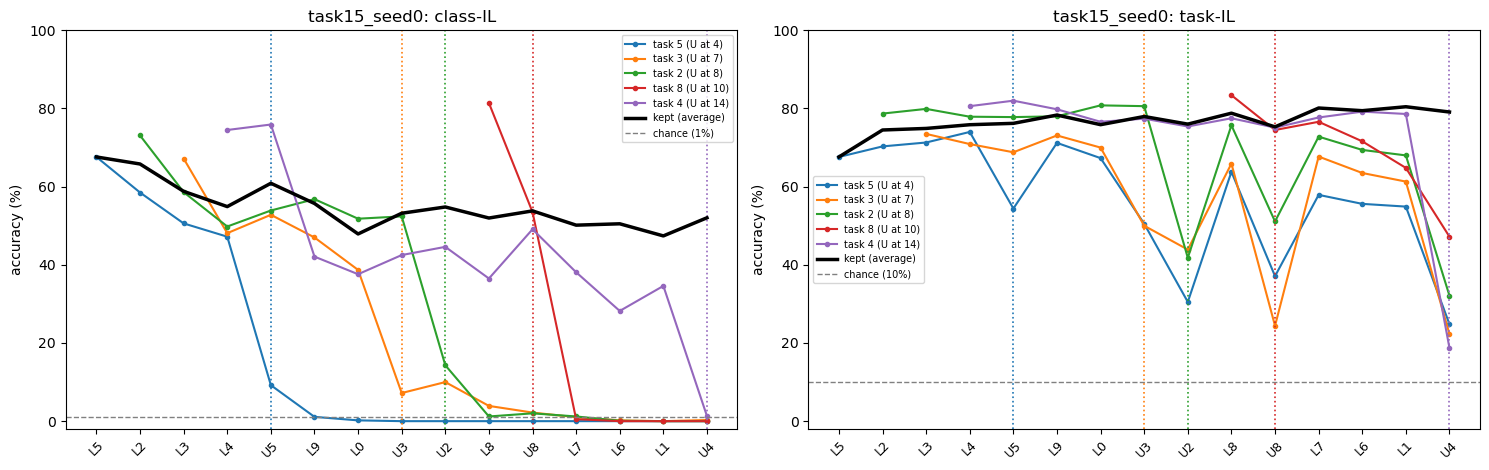

In [7]:
def item_series(acc, item):
    # Accuracy of one item (task or class) after every request; NaN before it was learned.
    cls = classes_of(item)
    s = acc[:, cls].mean(1)
    s[~learned_hist[:, cls[0]]] = np.nan
    return s


def kept_series(acc):
    out = np.full(R, np.nan)
    for r in range(R):
        kept = learned_hist[r] & ~forgotten_hist[r]
        if kept.any():
            out[r] = acc[r, kept].mean()
    return out


U_ROWS = [(r, i) for r, (k, i) in enumerate(REQUESTS) if k == "U"]
x = np.arange(R)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, acc, title, chance in [(axes[0], acc_cil, "class-IL", 1), (axes[1], acc_til, "task-IL", 10)]:
    for n, (r_u, item) in enumerate(U_ROWS[:8]):
        name = f"task {item}" if LEVEL == "task" else NAMES[item]
        line, = ax.plot(x, item_series(acc, item) * 100, marker="o", ms=3, label=f"{name} (U at {r_u})")
        ax.axvline(r_u, color=line.get_color(), ls=":", lw=1.2)
    ax.plot(x, kept_series(acc) * 100, color="black", lw=2.5, label="kept (average)")
    ax.axhline(chance, color="gray", ls="--", lw=1, label=f"chance ({chance}%)")
    ax.set(title=f"{SETTINGS['stream']}: {title}", ylabel="accuracy (%)", ylim=(-2, 100))
    ax.set_xticks(x, LABELS, rotation=90 if R > 30 else 45, fontsize=7 if R > 30 else 9)
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(RESULTS_DIR / f"12_{SETTINGS['stream']}_curves.png", dpi=120)
plt.show()

## 8. The full table as a picture

Task-IL accuracy of every task (rows) after every request (columns). White = not learned yet. A red box marks the request where (part of) that task was forgotten. A forgotten task's row should stay dark after its red box. A row that gets **lighter** again is relapse.

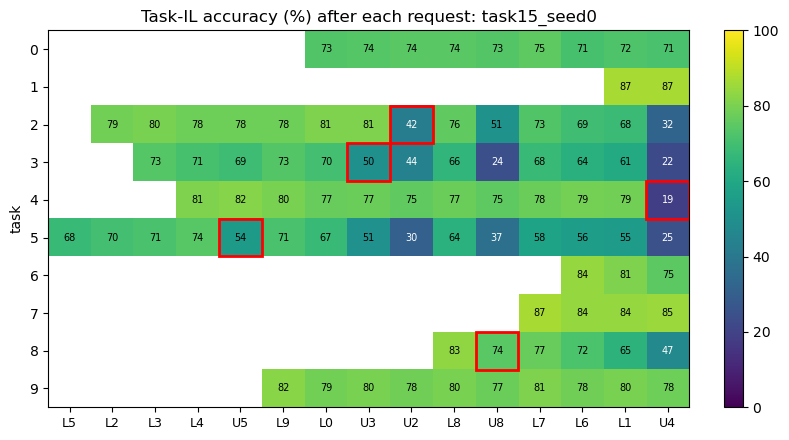

In [8]:
task_til = np.stack([acc_til[:, task_classes(t)].mean(1) for t in range(N_TASKS)])   # task x request
task_learned = np.stack([learned_hist[:, t * 10] for t in range(N_TASKS)])
shown = np.where(task_learned, task_til * 100, np.nan)

fig, ax = plt.subplots(figsize=(max(8, R * 0.45), 4.5))
im = ax.imshow(shown, aspect="auto", cmap="viridis", vmin=0, vmax=100)
for r_u, item in U_ROWS:
    t = item if LEVEL == "task" else item // 10
    ax.add_patch(plt.Rectangle((r_u - 0.5, t - 0.5), 1, 1, fill=False, ec="red", lw=2))
if R <= 30:
    for t in range(N_TASKS):
        for r in range(R):
            if task_learned[t, r]:
                ax.text(r, t, f"{shown[t, r]:.0f}", ha="center", va="center", fontsize=7,
                        color="white" if shown[t, r] < 50 else "black")
ax.set_xticks(np.arange(R), LABELS, rotation=90 if R > 30 else 0, fontsize=7 if R > 30 else 9)
ax.set(yticks=range(N_TASKS), ylabel="task", title=f"Task-IL accuracy (%) after each request: {SETTINGS['stream']}")
fig.colorbar(im, ax=ax, fraction=0.03)
fig.tight_layout()
fig.savefig(RESULTS_DIR / f"12_{SETTINGS['stream']}_heatmap.png", dpi=120)
plt.show()

## 9. Spill and relapse, in numbers

Rough numbers to read the plots by (program 13 defines the exact metrics):

**Spill** of a `U` at request r: for every *other* task that is learned and kept, how much its accuracy changed from request r−1 to r. We list the sum of absolute changes and the biggest single drop.

**Relapse** of a forgotten item: its accuracy right after its `U`, the highest it reached later, and at the end. *Rise* = end − right after. A positive rise means the item came back. "Later L's" is the number of tasks learned after it was forgotten (program 11): more later learning gives more chance to relapse.

In [9]:
def task_acc_kept(acc, r, t, kept):
    # Average accuracy at request r over the classes of task t that are in the kept mask.
    cls = [c for c in task_classes(t) if kept[c]]
    return acc[r, cls].mean() if cls else np.nan


print("SPILL: change in the other kept tasks at each U (percentage points)")
print(f"{'request':>10} | {'class-IL: sum |change|':>22} {'worst drop':>11} | {'task-IL: sum |change|':>21} {'worst drop':>11}")
spill = []
for r_u, item in U_ROWS:
    row = {}
    for name, acc in [("cil", acc_cil), ("til", acc_til)]:
        # Same classes before and after: those kept after this U (so the forgotten ones are left out of both).
        kept = learned_hist[r_u] & ~forgotten_hist[r_u]
        changes = [task_acc_kept(acc, r_u, t, kept) - task_acc_kept(acc, r_u - 1, t, kept) for t in range(N_TASKS)]
        changes = np.array([c for c in changes if np.isfinite(c)]) * 100
        row[name] = (np.abs(changes).sum(), changes.min() if len(changes) else 0.0)
    spill.append({"request": r_u, "item": item, "cil_sum": row["cil"][0], "cil_worst": row["cil"][1],
                  "til_sum": row["til"][0], "til_worst": row["til"][1]})
    print(f"{LABELS[r_u]:>6} [{r_u:2d}] | {row['cil'][0]:22.1f} {row['cil'][1]:+11.1f} | "
          f"{row['til'][0]:21.1f} {row['til'][1]:+11.1f}")

later = {pos: k for pos, _, k in learning_after_forget(REQUESTS)}
print("\nRELAPSE: accuracy of each forgotten item (%), task-IL (chance 10%) and class-IL")
print(f"{'item':>14} {'later Ls':>8} | {'before U':>8} {'after U':>8} {'max later':>9} {'end':>6} {'rise':>6} | "
      f"{'class-IL after':>14} {'end':>6}")
relapse = []
for r_u, item in U_ROWS:
    til, cil = item_series(acc_til, item) * 100, item_series(acc_cil, item) * 100
    after, end = til[r_u], til[-1]
    peak = np.nanmax(til[r_u:])
    relapse.append({"request": r_u, "item": item, "later_L": later[r_u], "before": til[r_u - 1], "after": after,
                    "max_later": peak, "end": end, "rise": end - after, "cil_after": cil[r_u], "cil_end": cil[-1]})
    name = f"task {item}" if LEVEL == "task" else NAMES[item]
    print(f"{name:>14} {later[r_u]:8d} | {til[r_u - 1]:8.1f} {after:8.1f} {peak:9.1f} {end:6.1f} {end - after:+6.1f} | "
          f"{cil[r_u]:14.1f} {cil[-1]:6.1f}")

SPILL: change in the other kept tasks at each U (percentage points)
   request | class-IL: sum |change|  worst drop | task-IL: sum |change|  worst drop
    U5 [ 4] |                   10.2        +1.4 |                   3.6        -2.1
    U3 [ 7] |                   12.0        +0.3 |                   2.9        -0.2
    U2 [ 8] |                    4.0        +0.7 |                   4.2        -2.0
    U8 [10] |                   34.9       +10.2 |                   5.9        -2.6
    U4 [14] |                   10.8        -0.2 |                   9.8        -5.9

RELAPSE: accuracy of each forgotten item (%), task-IL (chance 10%) and class-IL
          item later Ls | before U  after U max later    end   rise | class-IL after    end
        task 5        6 |     74.0     54.4      71.2   24.8  -29.6 |            9.2    0.0
        task 3        4 |     70.0     50.0      67.7   22.3  -27.7 |            7.2    0.3
        task 2        4 |     80.6     41.8      75.7   32.1   -9.

## 10. The unlearning steps in detail

One row per `U`: how much forget data came from the buffer, how much retain data there was, the bad teacher's seed and favourite class, the final KL values (low = the student matches its teachers), how many images were deleted from the buffer, and the carriers left. A growing number of carriers means more stored logits still "point at" forgotten classes, and DER++ keeps replaying those.

In [10]:
print(f"{'request':>10} {'forget(buf+top-up)':>19} {'retain':>7} {'bad seed':>8} {'favourite':>14} "
      f"{'KL forget':>9} {'KL retain':>9} {'deleted':>7} {'carriers':>9}")
for u in unlearn_log:
    kr = "-" if u["kl_retain_end"] is None else f"{u['kl_retain_end']:.3f}"
    print(f"{LABELS[u['request']]:>6} [{u['request']:2d}] {u['forget_from_buffer']:>11} + {u['forget_total'] - u['forget_from_buffer']:<5} "
          f"{u['retain_images']:7d} {u['bad_teacher_seed']:8d} {NAMES[u['bad_teacher_favourite']]:>14} "
          f"{u['kl_forget_end']:9.3f} {kr:>9} {u['removed_from_buffer']:7d} {u['carriers']:5d}/{u['buffer_after']}")

   request  forget(buf+top-up)  retain bad seed      favourite KL forget KL retain deleted  carriers
    U5 [ 4]         494 + 0        1506        5        raccoon     0.473     0.106     494   692/1506
    U3 [ 7]         326 + 0        1674        9          snake     0.312     0.076     326   764/1674
    U2 [ 8]         359 + 0        1315        9          snake     0.261     0.071     359   777/1315
    U8 [10]         857 + 0        1143       13     chimpanzee     0.537     0.134     857   672/1143
    U4 [14]         199 + 0        1801       14         spider     0.289     0.062     199   858/1801


## 11. Log the run

In [11]:
to_py = lambda d: {k: (round(float(v), 3) if isinstance(v, (float, np.floating)) else
                       int(v) if isinstance(v, np.integer) else v) for k, v in d.items()}
log_run("12_clu_naive", SETTINGS,
        {"stream": SETTINGS["stream"], "level": LEVEL, "minutes": round(minutes, 1),
         "final_kept_cil": float(kept_series(acc_cil)[-1]), "final_kept_til": float(kept_series(acc_til)[-1]),
         "final_forgotten_til": float(acc_til[-1, forgotten_hist[-1]].mean()) if forgotten_hist[-1].any() else None,
         "spill": [to_py(s) for s in spill], "relapse": [to_py(x) for x in relapse],
         "unlearn": [to_py(u) for u in unlearn_log]})
print("logged to", RESULTS_DIR / "runs.jsonl")

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## 12. Order alone: the worst-case vs best-case stream

Program 11 saved two streams that forget the **same** task (task 0) and learn the **same** tasks, in a different order:

- `handmade_worst`: `L0 → U0 → L1 → … → L9` (9 tasks learned after forgetting)
- `handmade_best`: `L0 → L1 → … → L9 → U0` (nothing learned after forgetting)

To fill this section: set `stream` in section 1 to `handmade_worst`, run the notebook from the top (about 15 minutes), then `handmade_best`, then run this cell. It plots **task 0's accuracy across the whole sequence** for both (the roadmap's plot). If task 0 ends higher in the worst case than right after its `U`, the later learning brought it back.

Note: in `handmade_worst`, the `U0` comes right after the first task, so there is no retain data; only the forget part of the loss is used.

In [12]:
pair = {name: RESULTS_DIR / f"12_{name}.npz" for name in ("handmade_worst", "handmade_best")}
if all(p.exists() for p in pair.values()):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
    for name, path in pair.items():
        d = np.load(path)
        labels = list(d["requests"])
        for ax, key, chance in [(axes[0], "acc_cil", 1), (axes[1], "acc_til", 10)]:
            s = d[key][:, task_classes(0)].mean(1) * 100
            line, = ax.plot(range(len(s)), s, marker="o", label=name)
            ax.axvline(labels.index("U0"), color=line.get_color(), ls=":", lw=1.2)
            ax.axhline(chance, color="gray", ls="--", lw=1)
        s_til = d["acc_til"][:, task_classes(0)].mean(1) * 100
        print(f"{name:>15}: task 0 task-IL right after U0 {s_til[labels.index('U0')]:.1f}%, at the end {s_til[-1]:.1f}%")
    axes[0].set(title="Task 0 accuracy, class-IL", xlabel="request number", ylabel="accuracy (%)", ylim=(-2, 100))
    axes[1].set(title="Task 0 accuracy, task-IL", xlabel="request number", ylabel="accuracy (%)", ylim=(-2, 100))
    for ax in axes:
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "12_worst_vs_best.png", dpi=120)
    plt.show()
else:
    print("run the notebook with stream = 'handmade_worst' and 'handmade_best' first; missing:",
          [p.name for p in pair.values() if not p.exists()])

run the notebook with stream = 'handmade_worst' and 'handmade_best' first; missing: ['12_handmade_worst.npz', '12_handmade_best.npz']


## 13. Optional: change the settings

Each run is logged, and its results are saved under the stream's name.
- `stream` = `class30_seed0`: class-level forgetting. Does a single forgotten class relapse more easily than a whole task (its 9 siblings in the task are still trained)? About 20 minutes.
- `purge_buffer` = False: forgotten images stay in the buffer and DER++ keeps replaying them **with their labels**. Expect strong relapse. This is program 15's "buffer leakage" cause. Note that the results file of the same stream is overwritten, so rename the old one first.
- `unlearn_steps` = 200: does stronger unlearning stop relapse, or only cause more spill?
- `stream` = `task15_seed1` and `task15_seed2`: does the pattern hold on other orders?

## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*

Questions to answer in it:
1. Did every `U` make its item's task-IL accuracy drop near chance (10%)? How fast, compared with program 09?
2. **Spill:** at which `U` did the kept tasks drop the most, and by how much? Is it bigger when the buffer had little retain data?
3. **Relapse:** which forgotten items rose again later? Do the ones with more later `L`s (program 11's prediction) rise more?
4. Is relapse visible in task-IL but not in class-IL? What does that say about *where* the forgotten knowledge sits (the head vs the features)?
5. The carriers column: do stored logits in the buffer still point at forgotten classes? Could DER++'s logit replay be teaching the forgotten classes back, even with their images deleted?
6. Worst vs best case (section 12): does order alone change task 0's final accuracy?